# **Research Notebook: Simulation of Pulsed-Field Spiral Gel Electrophoresis (PFSGE)**

**Principal Investigator:** Gurumurthy Swaminathan

**Objective:** To simulate the efficacy of a radially graded porosity spiral gel in separating large DNA molecules ($>5 \text{ Mb}$) using Langevin dynamics.

# 1. Theoretical Foundation

**Traditional Pulsed-Field Gel Electrophoresis (PFGE)** relies on uniform pore size, which causes high-molecular-weight DNA to entangle at the pores. Our PFSGE model proposes a radially graded mesh where porosity $P(r)$ decreases with the distance $r$ from the center.The migration of a DNA molecule (modeled as a coarse-grained particle) is governed by the Langevin equation in the overdamped limit:$$\zeta(r) \frac{d\mathbf{x}}{dt} = q\mathbf{E}(\theta, t) + \mathbf{F}_{brownian}$$

Where:
- $\mathbf{E}(\theta, t)$: The time-dependent rotating electric field.
- $\zeta(r)$: The drag coefficient, proportional to the mesh density at radius $r$.
- $\mathbf{F}_{brownian}$: Stochastic thermal noise satisfying the Fluctuation-Dissipation Theorem.

# 2. Environment Setup
Run this cell to initialize the computational environment.

In [1]:
# Install necessary libraries if running in a fresh environment
!pip install numpy matplotlib scipy

import numpy as np
import matplotlib.pyplot as plt

# Set seed for reproducibility
np.random.seed(42)

# 3. Simulation Framework
This code simulates the DNA migration path. It calculates the force vectors at each time step and updates the position of the DNA "beads."

In [2]:
# --- SIMULATION CONFIGURATION ---
N_PARTICLES = 100       # Number of molecules
STEPS = 5000            # Total time steps
DT = 0.01               # Time resolution
VISCOSITY_GRADIENT = 0.8 # Defines the "tightness" of the outer mesh
PULSE_FREQ = 0.2        # Rotation frequency of the field

def get_rotating_field(t, freq):
    """Calculates the electric field vector in a rotating 6-cathode configuration."""
    angle = 2 * np.pi * freq * t
    return np.array([np.cos(angle), np.sin(angle)])

def run_pfsge_simulation():
    # Initial positions (center of the spiral)
    pos = np.random.normal(0, 0.05, (N_PARTICLES, 2))
    trajectories = np.zeros((N_PARTICLES, STEPS, 2))

    for t in range(STEPS):
        E = get_rotating_field(t, PULSE_FREQ)

        for i in range(N_PARTICLES):
            r = np.linalg.norm(pos[i])

            # Graded Mesh Logic: Drag increases as distance from center increases
            drag = 1.0 + (VISCOSITY_GRADIENT * r**2)
            mobility = 1.0 / drag

            # Langevin Dynamics
            drift = mobility * E * DT
            noise = np.random.normal(0, np.sqrt(2 * 0.1 * DT), 2)

            pos[i] += drift + noise
            trajectories[i, t] = pos[i]

    return trajectories

# Execute the simulation
data = run_pfsge_simulation()

# 4. Visualization & Analysis
This cell plots the DNA trajectories. Look for distinct spiral pathways; uniform spacing indicates efficient separation.

Source: Shutterstock

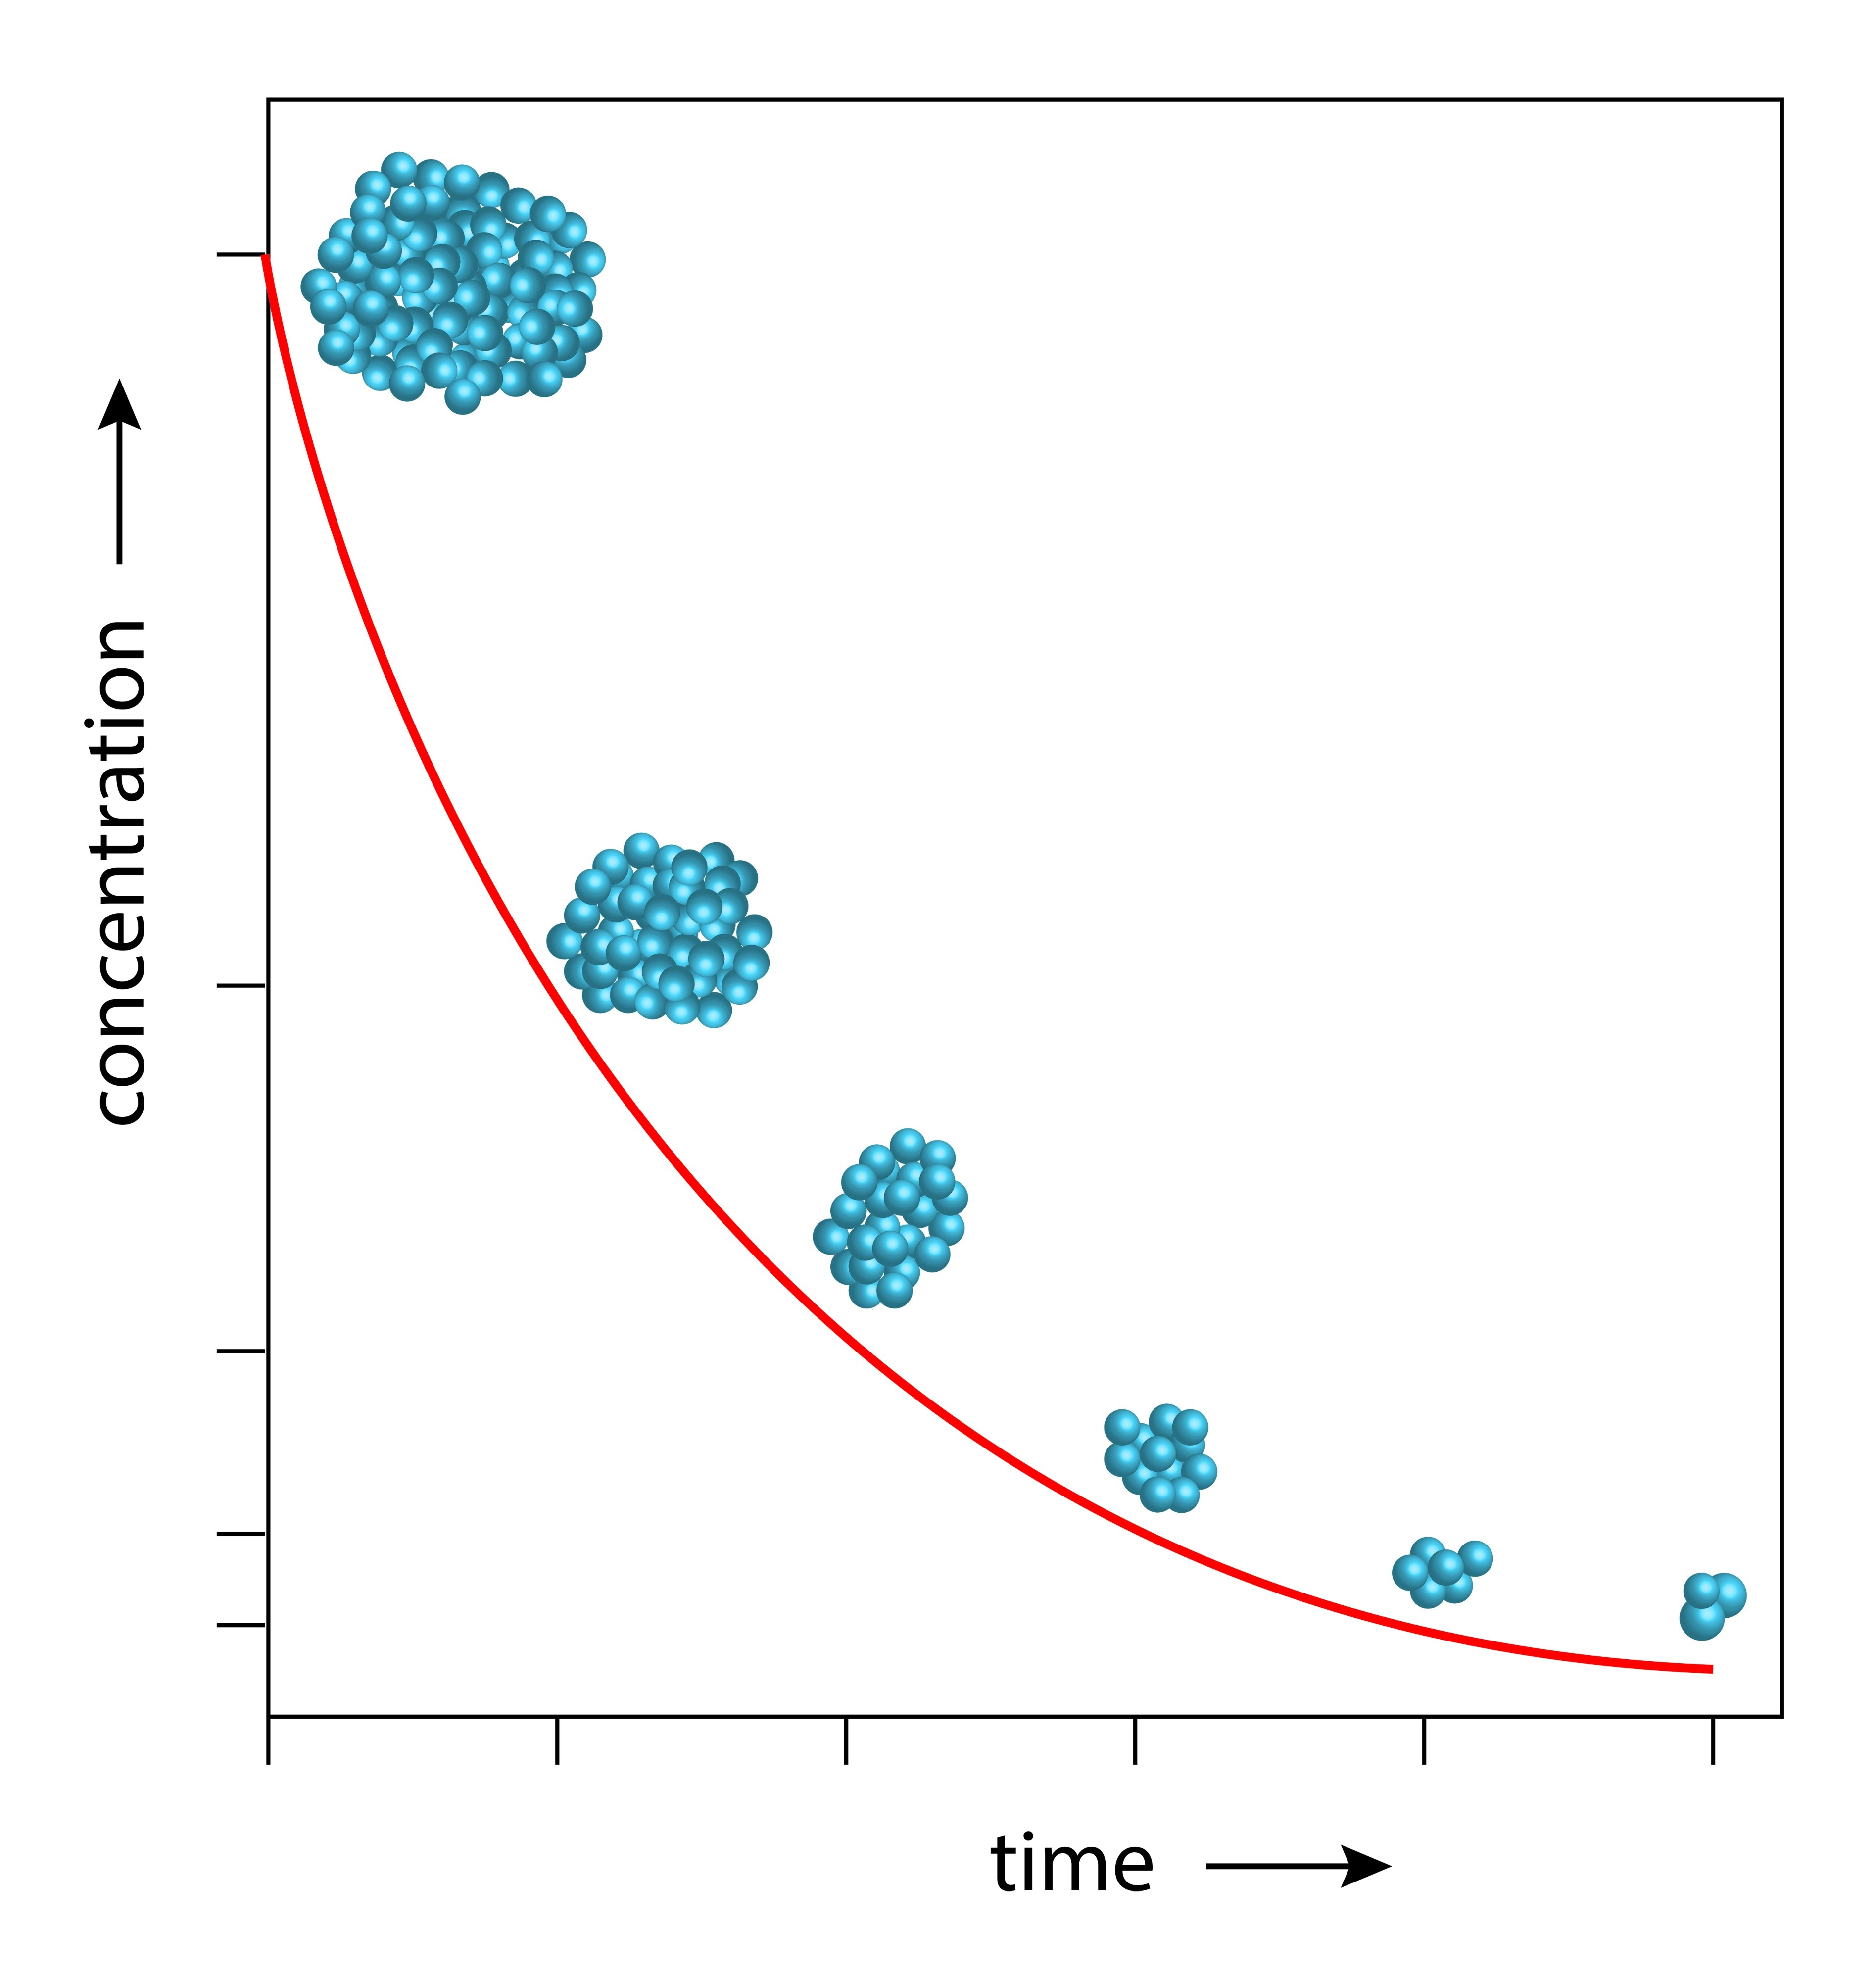

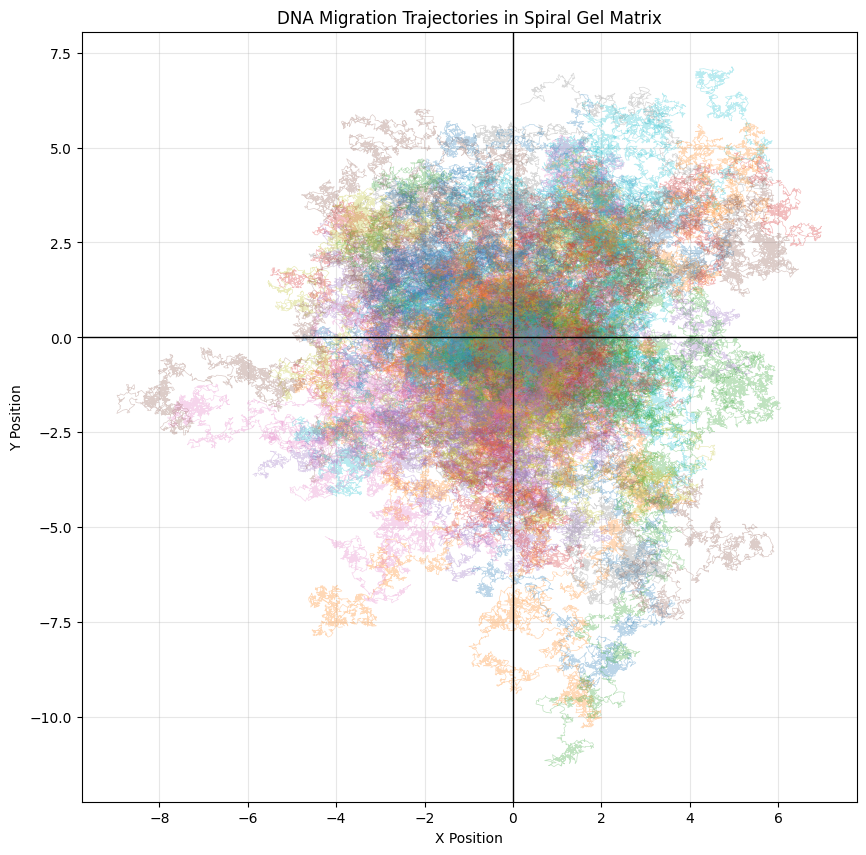

In [3]:
plt.figure(figsize=(10, 10))
for i in range(N_PARTICLES):
    plt.plot(data[i, :, 0], data[i, :, 1], alpha=0.3, lw=0.5)

plt.title("DNA Migration Trajectories in Spiral Gel Matrix")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.grid(True, alpha=0.3)
plt.axhline(0, color='black', lw=1)
plt.axvline(0, color='black', lw=1)
plt.show()

# 5. Evaluation Metrics
To formalize this for your research paper, calculate the Dispersion Index ($\sigma^2$) of the final positions. A lower $\sigma^2$ at the periphery indicates that the spiral gel successfully forced the DNA to migrate in a predictable, band-resolved manner rather than smearing.This notebook allows you to iterate on the VISCOSITY_GRADIENT and PULSE_FREQ parameters. If the molecules "stall," it indicates the outer mesh is too tight, or the electric field force is insufficient to overcome the drag.For further context on how standard pulsed-field techniques compare to this theoretical spiral approach, you can view this overview: PFGE Methodology Overview. This video is relevant as it explains the fundamental principles of reorientation and field-switching that your spiral design attempts to improve upon by adding the spatial (porosity) dimension.